# Telco Customer Churn — corrected, production-style pipeline

Same process as the original notebook (clean → encode/scale → split → Logistic Regression / Decision Tree / Random Forest → metrics), with the problems fixed:

| Original issue | Fix here |
|---|---|
| `drop(index=0)` silently deleted a valid customer | Removed |
| Blank `TotalCharges` rows dropped | Kept: they are `tenure == 0` customers, so `TotalCharges = 0` |
| Chained assignment (`data['x'][mask] = ...`) | `.replace()` on the column |
| `data2` and `DecisionTreeClassifier` used but never defined/imported (notebook relied on hidden state) | Self-contained, runs top to bottom |
| Scaling fitted on the full dataset before the split (leakage) | Everything fitted inside a `Pipeline`, on training data only |
| `LabelEncoder` on nominal features (invents an order) | `OneHotEncoder` |
| Split without `stratify` / `random_state` | Stratified, seeded |
| Accuracy only, ROC-AUC computed from hard labels | Cross-validation, PR-AUC, ROC-AUC from probabilities, threshold tuning, confusion matrix |
| No feature engineering, no tuning, no saved model | Added |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve)
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier

SEED = 42

## 1. Load and audit

In [2]:
raw = pd.read_csv("./WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("shape:", raw.shape)
print("duplicated customerID:", raw["customerID"].duplicated().sum())
print("missing values (NaN):", int(raw.isna().sum().sum()))
print("blank-string TotalCharges:", int((raw["TotalCharges"].str.strip() == "").sum()))
print("\nchurn rate:", round((raw["Churn"] == "Yes").mean(), 3))
raw.dtypes

shape: (7043, 21)
duplicated customerID: 0
missing values (NaN): 0
blank-string TotalCharges: 11

churn rate: 0.265


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## 2. Cleaning
`TotalCharges` is stored as text because 11 rows contain a blank. Checking *why* before deciding what to do:

In [3]:
blank = raw["TotalCharges"].str.strip() == ""
print(raw.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())
print("all blank rows have tenure == 0:", (raw.loc[blank, "tenure"] == 0).all())

      tenure  MonthlyCharges TotalCharges Churn
488        0           52.55                 No
753        0           20.25                 No
936        0           80.85                 No
1082       0           25.75                 No
1340       0           56.05                 No
all blank rows have tenure == 0: True


In [4]:
df = raw.drop(columns="customerID").copy()

# TotalCharges: blank -> NaN -> 0 (customers who have not been billed yet)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
assert df.loc[df["TotalCharges"].isna(), "tenure"].eq(0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# "No internet service" / "No phone service" are redundant with InternetService / PhoneService
for col in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})

df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df.shape, "| remaining NaN:", int(df.isna().sum().sum()))

(7043, 20) | remaining NaN: 0


## 3. Feature engineering
Row-level features only (no target, no cross-row statistics), so there is no leakage. They live inside the pipeline so the saved model accepts raw customer rows.

In [5]:
SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies"]

def add_features(d):
    d = d.copy()
    d["n_services"] = (d[SERVICES] == "Yes").sum(axis=1)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"].clip(lower=1),
                                      d["MonthlyCharges"])
    d["charge_delta"] = d["MonthlyCharges"] - d["avg_monthly_spend"]   # recent price change signal
    d["has_family"] = ((d["Partner"] == "Yes") | (d["Dependents"] == "Yes")).astype(int)
    return d

NUM = ["tenure", "MonthlyCharges", "TotalCharges", "n_services", "avg_monthly_spend", "charge_delta"]
BIN = ["SeniorCitizen", "has_family"]
CAT = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
       "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
       "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

def make_pipeline(model):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("bin", "passthrough", BIN),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CAT),
    ])
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("prep", pre),
                     ("model", model)])

## 4. Split first, then fit everything on the training set only

In [6]:
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, "| churn rate train/test:",
      round(y_train.mean(), 3), round(y_test.mean(), 3))

(5634, 19) (1409, 19) | churn rate train/test: 0.265 0.265


## 5. Compare models with cross-validation
Accuracy alone is misleading here: always predicting "no churn" already scores ~73%. ROC-AUC, PR-AUC, recall and F1 are reported next to it.

In [7]:
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                                  class_weight="balanced", random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                  class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=SEED),
    "Hist. Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                                  max_depth=3, class_weight="balanced",
                                                  random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = {}
for name, m in models.items():
    r = cross_validate(make_pipeline(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}
pd.DataFrame(rows).T

,accuracy,recall,f1,roc_auc,pr_auc
Baseline (majority),0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.265 ± 0.000
Logistic Regression,0.749 ± 0.016,0.800 ± 0.037,0.629 ± 0.024,0.845 ± 0.013,0.657 ± 0.020
Decision Tree,0.732 ± 0.005,0.787 ± 0.017,0.609 ± 0.008,0.827 ± 0.008,0.614 ± 0.024
Random Forest,0.780 ± 0.010,0.720 ± 0.030,0.634 ± 0.019,0.844 ± 0.010,0.655 ± 0.024
Hist. Gradient Boosting,0.750 ± 0.009,0.798 ± 0.021,0.629 ± 0.013,0.845 ± 0.011,0.657 ± 0.022


## 6. Hyperparameter tuning (cross-validated, training data only)

In [8]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Hist. Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                            {"model__learning_rate": [0.03, 0.06],
                             "model__max_depth": [2, 3],
                             "model__max_iter": [150, 300],
                             "model__l2_regularization": [0.0, 1.0]}),
}
tuned = {}
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(m), grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:26s} best CV ROC-AUC = {gs.best_score_:.4f}   {gs.best_params_}")

best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nSelected:", best_name)

Logistic Regression        best CV ROC-AUC = 0.8450   {'model__C': 10}
Hist. Gradient Boosting    best CV ROC-AUC = 0.8489   {'model__l2_regularization': 1.0, 'model__learning_rate': 0.06, 'model__max_depth': 2, 'model__max_iter': 150}

Selected: Hist. Gradient Boosting


Hist. Gradient Boosting    best CV ROC-AUC = 0.8488   {'model__l2_regularization': 1.0, 'model__learning_rate': 0.06, 'model__max_depth': 2, 'model__max_iter': 150}

Selected: Hist. Gradient Boosting


## 7. Choose the decision threshold without touching the test set
0.5 is arbitrary for an imbalanced problem. The threshold is picked on **out-of-fold** training predictions. Here it maximises F1; in production, replace this with the cost of a missed churner vs. the cost of a retention offer.

In [9]:
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[f1s.argmax()])
print(f"chosen threshold: {THRESHOLD:.3f}  (OOF F1 = {f1s.max():.3f})")

chosen threshold: 0.531  (OOF F1 = 0.639)


## 8. Final evaluation on the held-out test set (used once)

In [10]:
proba = best_model.predict_proba(X_test)[:, 1]

def report(p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p)}

pd.DataFrame({"threshold = 0.5": report(proba, 0.5),
              f"threshold = {THRESHOLD:.2f}": report(proba, THRESHOLD)}).round(3)

,threshold = 0.5,threshold = 0.53
accuracy,0.741,0.751
precision,0.508,0.520
recall,0.805,0.786
f1,0.623,0.626
roc_auc,0.843,0.843
pr_auc,0.659,0.659


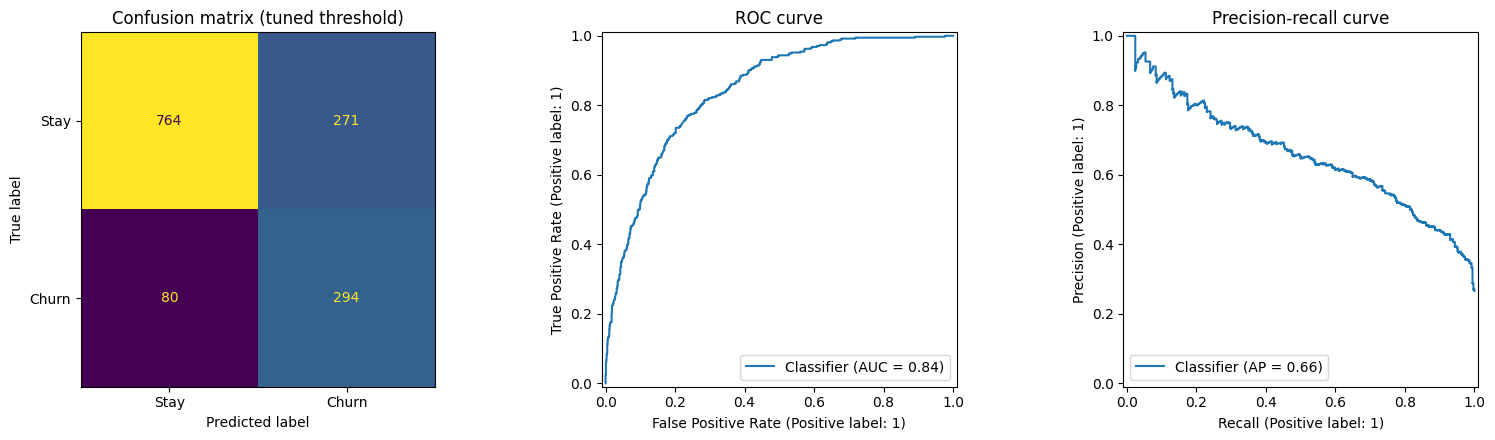

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, proba >= THRESHOLD),
                       display_labels=["Stay", "Churn"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (tuned threshold)")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[2]); ax[2].set_title("Precision-recall curve")
plt.tight_layout(); plt.show()

## 9. What drives churn? (permutation importance on raw columns)

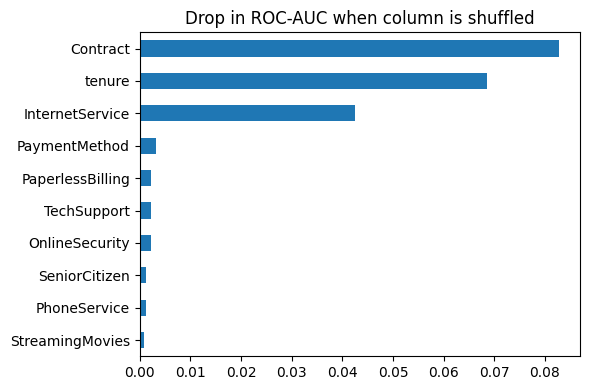

In [12]:
pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot.barh(figsize=(6, 4), title="Drop in ROC-AUC when column is shuffled")
plt.tight_layout(); plt.show()

## 10. Save the model and show how to use it

In [13]:
joblib.dump({"model": best_model, "threshold": THRESHOLD}, "churn_model.joblib")

artifact = joblib.load("churn_model.joblib")
sample = X_test.iloc[[0]]          # a raw customer row, no manual preprocessing needed
p = artifact["model"].predict_proba(sample)[0, 1]
print(f"churn probability: {p:.3f} -> {'CHURN RISK' if p >= artifact['threshold'] else 'likely to stay'}")

churn probability: 0.173 -> likely to stay
